In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = np.load("dayabay_analysis_dataset_npz_1-0-0/npz/dayabay_dataset/dayabay_background_rates.npz", allow_pickle=True)
arr = data['6AD']
print(arr)

[('accidentals_rate', 8.39901  , 8.18397  , 6.65972  , 0, 2.62981  , 2.60203  , 2.54534  , 0)
 ('accidentals_uncertainty', 0.0257708, 0.0252693, 0.0217033, 0, 0.0128695, 0.0128775, 0.0127418, 0)
 ('lithium_helium_rate', 2.92     , 2.92     , 2.45     , 0, 0.26     , 0.26     , 0.26     , 0)
 ('lithium_helium_uncertainty', 0.78     , 0.78     , 0.57     , 0, 0.04     , 0.04     , 0.04     , 0)
 ('fast_neutrons_rate', 0.791    , 0.791    , 0.503    , 0, 0.04     , 0.04     , 0.04     , 0)
 ('fast_neutrons_uncertainty', 0.1582   , 0.1582   , 0.1006   , 0, 0.008    , 0.008    , 0.008    , 0)
 ('amc_rate', 0.277217 , 0.268434 , 0.296314 , 0, 0.230175 , 0.22248  , 0.219081 , 0)
 ('amc_uncertainty', 0.117613 , 0.113887 , 0.125715 , 0, 0.0976551, 0.0943905, 0.0929483, 0)
 ('alpha_neutron_rate', 0.09     , 0.07     , 0.05     , 0, 0.05     , 0.04     , 0.04     , 0)
 ('alpha_neutron_uncertainty', 0.045    , 0.035    , 0.025    , 0, 0.025    , 0.02     , 0.02     , 0)]


In [9]:
import numpy as np

base_path = "dayabay_full_dataset_npz_1-0-0/npz/dayabay_dataset"
detectors = ["AD11", "AD12", "AD21", "AD22", "AD31", "AD32", "AD33", "AD34"]

events = {}
for detector in detectors:
    data = np.load(f"{base_path}/dayabay_events_{detector}.npz")
    events[detector] = data["events"]
    data.close()

# print(events)

In [10]:
def count_events_by_period(events, n_days=7):
    n_periods = max(
        (int(data["day"].max() // n_days) + 1 for data in events.values() if len(data)),
        default=0,
    )

    return {
        detector: np.bincount(
            (data["day"] // n_days).astype(int),
            minlength=n_periods,
        )
        for detector, data in events.items()
    }


weekly_counts = count_events_by_period(events)
monthly_counts = count_events_by_period(events, n_days=30)

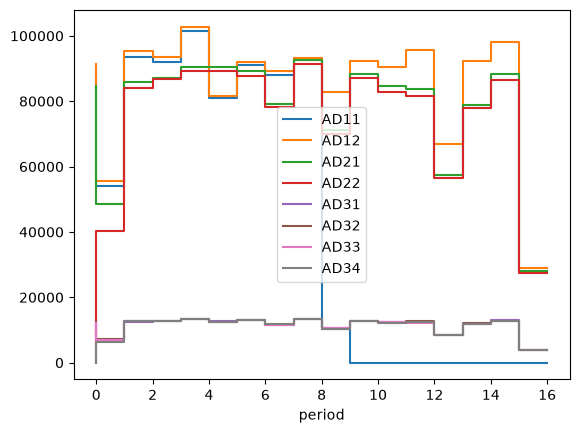

In [11]:
import pandas as pd


def analyze_correlations(events, n_days=200):
    detectors = list(events)

    max_period = max(
        int(data["day"].max() // n_days)
        for data in events.values()
    )

    counts = pd.DataFrame(
        0,
        index=pd.RangeIndex(max_period + 1, name="period"),
        columns=detectors,
        dtype=int,
    )

    for detector, data in events.items():
        periods, numbers = np.unique(
            (data["day"] // n_days).astype(int),
            return_counts=True,
        )
        counts.loc[periods, detector] = numbers

    counts.plot(drawstyle="steps")

analyze_correlations(events)


In [50]:

data = np.load("dayabay_analysis_dataset_npz_1-0-0/npz/dayabay_dataset/dayabay_background_spectra_8AD.npz", allow_pickle=True)
print(data.files)

['spectrum_shape_accidentals_AD11', 'spectrum_shape_lithium_helium_AD11', 'spectrum_shape_fast_neutrons_AD11', 'spectrum_shape_alpha_neutron_AD11', 'spectrum_shape_amc_AD11', 'spectrum_shape_accidentals_AD12', 'spectrum_shape_lithium_helium_AD12', 'spectrum_shape_fast_neutrons_AD12', 'spectrum_shape_alpha_neutron_AD12', 'spectrum_shape_amc_AD12', 'spectrum_shape_accidentals_AD21', 'spectrum_shape_lithium_helium_AD21', 'spectrum_shape_fast_neutrons_AD21', 'spectrum_shape_alpha_neutron_AD21', 'spectrum_shape_amc_AD21', 'spectrum_shape_accidentals_AD22', 'spectrum_shape_lithium_helium_AD22', 'spectrum_shape_fast_neutrons_AD22', 'spectrum_shape_alpha_neutron_AD22', 'spectrum_shape_amc_AD22', 'spectrum_shape_accidentals_AD31', 'spectrum_shape_lithium_helium_AD31', 'spectrum_shape_fast_neutrons_AD31', 'spectrum_shape_alpha_neutron_AD31', 'spectrum_shape_amc_AD31', 'spectrum_shape_accidentals_AD32', 'spectrum_shape_lithium_helium_AD32', 'spectrum_shape_fast_neutrons_AD32', 'spectrum_shape_alp

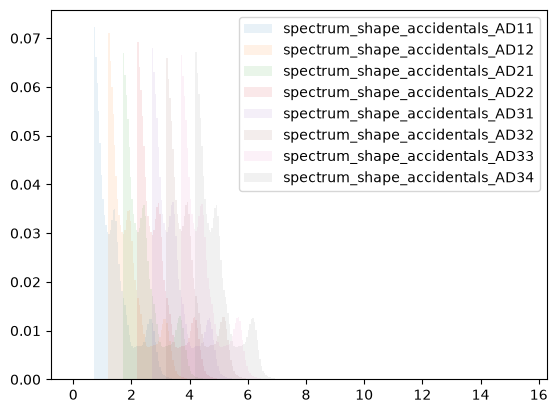

In [7]:
data = np.load("dayabay_analysis_dataset_npz_1-0-0/npz/dayabay_dataset/dayabay_background_spectra_8AD.npz", allow_pickle=True)

detectors = ["AD11", "AD12", "AD21", "AD22", "AD31", "AD32", "AD33", "AD34"]
for i, detector in enumerate(detectors):
        name = f"spectrum_shape_accidentals_{detector}"
        arr = data[name]
        left = arr[arr.dtype.names[0]]
        right = arr[arr.dtype.names[1]]
        counts = arr[arr.dtype.names[2]]

        plt.bar(left + i/2, counts, width=right-left, align='edge', alpha=0.1, label=name)

# plt.bar(arr[])
plt.legend()
plt.show()

In [ ]:

data = np.load("dayabay_analysis_dataset_npz_1-0-0/npz/dayabay_dataset/dayabay_background_spectra_6AD.npz", allow_pickle=True)
print(data.files)

['spectrum_shape_accidentals_AD11', 'spectrum_shape_lithium_helium_AD11', 'spectrum_shape_fast_neutrons_AD11', 'spectrum_shape_alpha_neutron_AD11', 'spectrum_shape_amc_AD11', 'spectrum_shape_accidentals_AD12', 'spectrum_shape_lithium_helium_AD12', 'spectrum_shape_fast_neutrons_AD12', 'spectrum_shape_alpha_neutron_AD12', 'spectrum_shape_amc_AD12', 'spectrum_shape_accidentals_AD21', 'spectrum_shape_lithium_helium_AD21', 'spectrum_shape_fast_neutrons_AD21', 'spectrum_shape_alpha_neutron_AD21', 'spectrum_shape_amc_AD21', 'spectrum_shape_accidentals_AD31', 'spectrum_shape_lithium_helium_AD31', 'spectrum_shape_fast_neutrons_AD31', 'spectrum_shape_alpha_neutron_AD31', 'spectrum_shape_amc_AD31', 'spectrum_shape_accidentals_AD32', 'spectrum_shape_lithium_helium_AD32', 'spectrum_shape_fast_neutrons_AD32', 'spectrum_shape_alpha_neutron_AD32', 'spectrum_shape_amc_AD32', 'spectrum_shape_accidentals_AD33', 'spectrum_shape_lithium_helium_AD33', 'spectrum_shape_fast_neutrons_AD33', 'spectrum_shape_alp

In [43]:
seed, N, p, M = input().split()
N, M, seed = int(N), int(M), int(seed)
p = float(p)


diff = [N] * (M + 1)
total = [N] * (M + 1)

np.random.seed(seed)
for i in range(M):
    res = np.random.binomial(1, p, total[i])
    total[i + 1] = total[i] - np.sum(res)
    # diff[i + 1] = diff[i] - np.sum(1 - res)
    diff[i + 1] = diff[i] + np.sum(res)

for i in range(1, len(diff)):
    print((diff[i] - diff[i - 1])/diff[i])

print(total)

0.3106642990283124
0.14622157352041057
0.07311559543343923
0.03863193931664093
0.021856712546885645
0.011063132092011494
0.006507592190889371
[62500, np.int64(34333), np.int64(18805), np.int64(10428), np.int64(5824), np.int64(3161), np.int64(1798), np.int64(991)]


In [31]:
import numpy as np

seed, N, p, M = input().split()
seed, N, M = int(seed), int(N), int(M)
p = float(p)

np.random.seed(seed)

# 1 represents heads; 0 represents tails
flips = np.random.binomial(1, p, size=(M, N))

# A coin survives only if it lands tails in every iteration so far
survived = np.cumprod(flips == 0, axis=0)

diff = np.concatenate(([N], survived.sum(axis=1)))

result = diff[1:] / diff[:-1]

print(*(f"{x:.3f}" for x in result))

0.506 0.514 0.495 0.493 0.520 0.515 0.535 0.560 0.549


In [44]:
import numpy as np

seed, N, p, M = input().split()
seed = int(seed)
N = int(N)
p = float(p)
M = int(M)

np.random.seed(seed)

diff = []

for _ in range(M):
    tosses = np.random.binomial(1, p, size=N)
    heads = np.sum(tosses)

    diff.append((N - heads) / N)
    N = heads

print(*[f"{x:.3f}" for x in diff])

0.549 0.548 0.551 0.554 0.556 0.564 0.585
